# Bott index and spin Bott index
A Chern number is defined in the Brillouin zone, so it needs a crystal. We will now see an
invariant that needs only the occupied states of one sample, the Bott index, with
`h.get_bott_index()`, and its spinful version, the spin Bott index, with
`h.get_spin_bott_index()`. The sample is a periodic supercell, closed into a torus. With $P$ the
projector on the occupied states and $X$, $Y$ the fractional coordinates along the two lattice
vectors of the supercell, we take the projected position operators

$$
U = P e^{2\pi i X} P, \qquad V = P e^{2\pi i Y} P, \qquad
B = \frac{1}{2\pi}\,{\rm Im}\,{\rm Tr}\log\left(VUV^\dagger U^\dagger\right).
$$

In a trivial insulator $U$ and $V$ almost commute and $B=0$. In a Chern insulator they cannot, and
$B$ is the Chern number. The spin Bott index splits the occupied states by the sign of
$P s_z P$ into two halves, and $B_s=(B_+-B_-)/2$. With time reversal its parity is the $Z_2$
invariant. Because nothing here needs a Bloch momentum, both work for a disordered sample, which
is what we do below.

### Import the necessary libraries

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry

### The clean Bott index is the Chern number
We take the Haldane model and grow a sublattice imbalance $M$, which closes the gap at
$M_c=4.5\,t_2=0.675$ for $t_2=0.15$ (the Haldane hopping of `h.add_haldane()` carries a factor
$\sqrt3/2$, so the clean gap at $M=0$ is $9t_2=1.35$). We compare the Bott index of a $10\times10$
supercell with the Chern number of the primitive cell on a k-mesh.

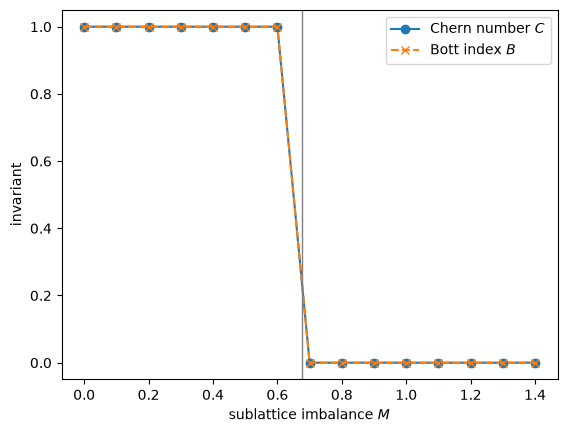

In [2]:
def haldane(M):
    h = geometry.honeycomb_lattice().get_hamiltonian(has_spin=False) # spinless honeycomb
    h.add_haldane(0.15) # Haldane coupling
    h.add_sublattice_imbalance(M) # sublattice imbalance
    return h

Ms = np.linspace(0.,1.4,15) # sublattice imbalance
C = [haldane(M).get_chern(nk=30) for M in Ms] # Chern number, k-space
B = [haldane(M).get_supercell(10).get_bott_index() for M in Ms] # Bott index, one sample
plt.plot(Ms,C,marker="o",label="Chern number $C$")
plt.plot(Ms,B,marker="x",ls="--",label="Bott index $B$")
plt.axvline(4.5*0.15,color="gray",lw=1)
plt.xlabel("sublattice imbalance $M$") ; plt.ylabel("invariant")
plt.legend() ; plt.show()

The two curves are on top of each other. $B$ is $1$ below the critical imbalance and $0$
above it, and the two jump between the same two points, $M=0.6$ and $M=0.7$. Close to $M_c$ the
gap is small, and a supercell smaller than the decay length of the states would give a non-integer
$B$; at $M=0.6$ and $0.7$ the gap is $0.15$ and $0.05$, and the $10\times10$ supercell is still
large enough.

### Phase diagram with disorder
Now we add Anderson disorder, an onsite energy at every site drawn uniformly between $-W/2$ and
$W/2$, and average $B$ over eight samples. Every sample gives an integer, so the average is the
fraction of samples that are topological.

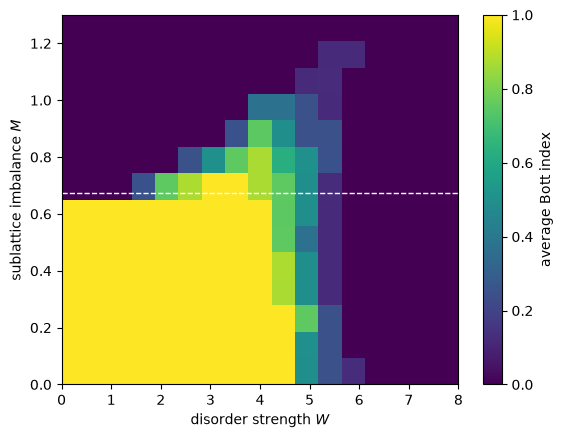

In [3]:
Ms = np.linspace(0.,1.3,14) # sublattice imbalance
Ws = np.linspace(0.,8.,17) # disorder strength
nsamples = 8
Bmap = np.zeros((len(Ms),len(Ws)))
for (i,M) in enumerate(Ms):
    hs = haldane(M).get_supercell(10) # 200 sites
    for (j,W) in enumerate(Ws):
        bs = []
        for s in range(nsamples):
            rng = np.random.default_rng(s)
            h = hs.copy()
            h.add_onsite(W*(rng.random(len(h.geometry.r))-0.5)) # Anderson disorder
            bs.append(h.get_bott_index())
        Bmap[i,j] = np.mean(bs)

plt.imshow(Bmap,origin="lower",aspect="auto",cmap="viridis",vmin=0,vmax=1,
           extent=[Ws[0],Ws[-1],Ms[0],Ms[-1]])
plt.colorbar(label="average Bott index")
plt.axhline(4.5*0.15,color="white",lw=1,ls="--")
plt.xlabel("disorder strength $W$") ; plt.ylabel("sublattice imbalance $M$")
plt.show()

For small $M$ every sample keeps $B=1$ up to $W\approx4$, three times the clean gap, and above
$W\approx6.5$ every sample is an Anderson insulator, $B=0$. Above the dashed line, for $M$ between
$0.7$ and $1.0$, the clean system is trivial, but at intermediate disorder, $W$ between $1.5$ and
$5$, many samples give $B=1$: this is what is called a topological Anderson insulator. You can think of it as the disorder renormalizing the sublattice
mass downward, so that the effective mass falls below $M_c$. The edges of the regions are not
sharp, and the average there is not $1$, because the samples have only 200 sites.

### Spin Bott index with Rashba coupling
For the Kane-Mele model the Bott index is zero by time reversal, and the invariant is $B_s$. A
Rashba coupling breaks the conservation of $s_z$, and $B_s$ stays an integer while $P s_z P$
keeps its gap. We compare it with the spin Chern number of the k-space routine.

In [4]:
rs = [0.,0.05,0.1,0.15,0.2] # Rashba coupling
Cs,Bs = [],[]
for r in rs:
    h = geometry.honeycomb_lattice().get_hamiltonian(has_spin=True) # spinful honeycomb
    h.add_kane_mele(0.2) # spin-orbit coupling
    h.add_rashba(r) # Rashba coupling, s_z is not conserved
    h.add_sublattice_imbalance(0.2) # sublattice imbalance
    Cs.append(h.get_spin_chern(nk=20,write=False)) # spin Chern number, k-space
    Bs.append(h.get_supercell(6).get_spin_bott_index()) # spin Bott index, 72 sites
    print("Rashba =",r,"  C_s =",round(Cs[-1],3),"  B_s =",round(Bs[-1],3))

Rashba = 0.0   C_s = 1.0   B_s = 1.0


Rashba = 0.05   C_s = 1.0   B_s = 1.0


Rashba = 0.1   C_s = 1.0   B_s = 1.0


Rashba = 0.15   C_s = 1.0   B_s = 1.0


Rashba = 0.2   C_s = 1.0   B_s = 1.0


Both stay at $1$ for every Rashba coupling of the list. A larger Rashba coupling closes the gap
of the Hamiltonian and then neither is defined.

### The quantum spin Hall insulator with disorder

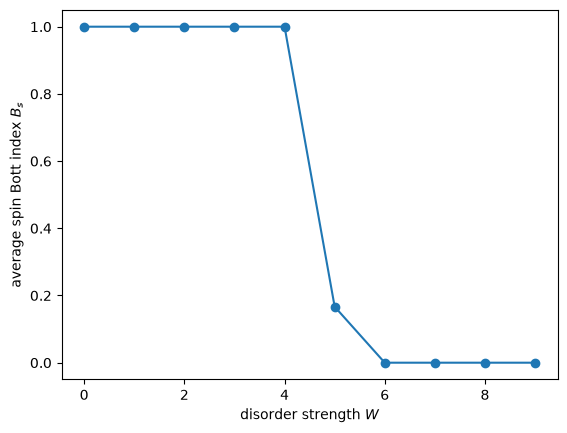

In [5]:
h = geometry.honeycomb_lattice().get_hamiltonian(has_spin=True)
h.add_kane_mele(0.1) # spin-orbit coupling
h.add_rashba(0.05) # Rashba coupling
hs = h.get_supercell(10) # 200 sites
Ws = np.linspace(0.,9.,10) # disorder strength
Bsw = []
for W in Ws:
    bs = []
    for s in range(6):
        rng = np.random.default_rng(s)
        hd = hs.copy()
        hd.add_onsite(W*(rng.random(len(hd.geometry.r))-0.5)) # Anderson disorder
        bs.append(hd.get_spin_bott_index())
    Bsw.append(np.mean(bs))
plt.plot(Ws,Bsw,marker="o")
plt.xlabel("disorder strength $W$") ; plt.ylabel("average spin Bott index $B_s$")
plt.show()

$B_s=1$ survives up to $W\approx4$ and goes to zero above $W\approx6$, the same Anderson
transition as for the Chern insulator.

### Comparison with the literature
The Bott index is the invariant of Ref. [1], built from the projected position operators of a
finite torus. Its equality with the Chern number, up to corrections of order $1/L$, is Ref. [2].
The spin Bott index and the unitary part taken with a singular value decomposition are Ref. [3],
its Eqs. (5) to (11); its Fig. 1(b) shows $B_s$ of the Kane-Mele model against the sublattice
imbalance, and its Fig. 3 against the Rashba coupling, with $B_s=1$ up to
$\lambda_R/\lambda_{SO}\approx3$, as in the third cell here. The region of the phase diagram where
disorder makes a trivial insulator topological is the topological Anderson insulator of
Ref. [4], explained in Ref. [5] by a disorder-renormalized mass.

[1] T. A. Loring and M. B. Hastings, *Disordered topological insulators via C\*-algebras*,
EPL **92**, 67004 (2010), [arXiv:1005.4883](https://arxiv.org/abs/1005.4883)

[2] D. Toniolo, *On the Bott index of unitary matrices on a finite torus*,
[arXiv:1708.05912](https://arxiv.org/abs/1708.05912)

[3] H. Huang and F. Liu, *Theory of spin Bott index for quantum spin Hall states in
non-periodic systems*, Phys. Rev. B **98**, 125130 (2018),
[arXiv:1810.00081](https://arxiv.org/abs/1810.00081)

[4] J. Li, R.-L. Chu, J. K. Jain and S.-Q. Shen, *Topological Anderson Insulator*,
Phys. Rev. Lett. **102**, 136806 (2009), [arXiv:0811.3045](https://arxiv.org/abs/0811.3045)

[5] C. W. Groth, M. Wimmer, A. R. Akhmerov, J. Tworzydło and C. W. J. Beenakker, *Theory of the
Topological Anderson Insulator*, Phys. Rev. Lett. **103**, 196805 (2009),
[arXiv:0908.0881](https://arxiv.org/abs/0908.0881)